In [30]:
import pandas as pd

In [31]:
import os

print(os.getcwd())

d:\DA\Notebook


In [32]:
import os

print(os.listdir("../dataset/Cleaned"))

['Cleaned_Master_Environmental_Impact_Dataset.csv']


In [33]:
import pandas as pd

df = pd.read_csv("../dataset/Cleaned/Cleaned_Master_Environmental_Impact_Dataset.csv")

In [34]:
df.head()

,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good
2,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate
3,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good
4,France,Punaauia,22,Good,0,Good,22,Good,0,Good,6,Good


In [35]:
df.shape

(23463, 12)

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23463 entries, 0 to 23462
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Country             23463 non-null  object
 1   City                23463 non-null  object
 2   AQI Value           23463 non-null  int64 
 3   AQI Category        23463 non-null  object
 4   CO AQI Value        23463 non-null  int64 
 5   CO AQI Category     23463 non-null  object
 6   Ozone AQI Value     23463 non-null  int64 
 7   Ozone AQI Category  23463 non-null  object
 8   NO2 AQI Value       23463 non-null  int64 
 9   NO2 AQI Category    23463 non-null  object
 10  PM2.5 AQI Value     23463 non-null  int64 
 11  PM2.5 AQI Category  23463 non-null  object
dtypes: int64(5), object(7)
memory usage: 2.1+ MB


In [37]:
df.describe()


,AQI Value,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value
count,23463.000000,23463.000000,23463.000000,23463.000000,23463.000000
mean,72.010868,1.368367,35.193709,3.063334,68.519755
std,56.055220,1.832064,28.098723,5.254108,54.796443
min,6.000000,0.000000,0.000000,0.000000,0.000000
25%,39.000000,1.000000,21.000000,0.000000,35.000000
50%,55.000000,1.000000,31.000000,1.000000,54.000000
75%,79.000000,1.000000,40.000000,4.000000,79.000000
max,500.000000,133.000000,235.000000,91.000000,500.000000


In [38]:
df.describe(include="object")

,Country,City,AQI Category,CO AQI Category,Ozone AQI Category,NO2 AQI Category,PM2.5 AQI Category
count,23463,23463,23463,23463,23463,23463,23463
unique,176,23463,6,3,5,2,6
top,United States of America,Praskoveya,Good,Good,Good,Good,Good
freq,2872,1,9936,23460,21069,23448,10208


In [39]:
df.isnull().sum()

Country               0
City                  0
AQI Value             0
AQI Category          0
CO AQI Value          0
CO AQI Category       0
Ozone AQI Value       0
Ozone AQI Category    0
NO2 AQI Value         0
NO2 AQI Category      0
PM2.5 AQI Value       0
PM2.5 AQI Category    0
dtype: int64

In [40]:
df.duplicated().sum()

0

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

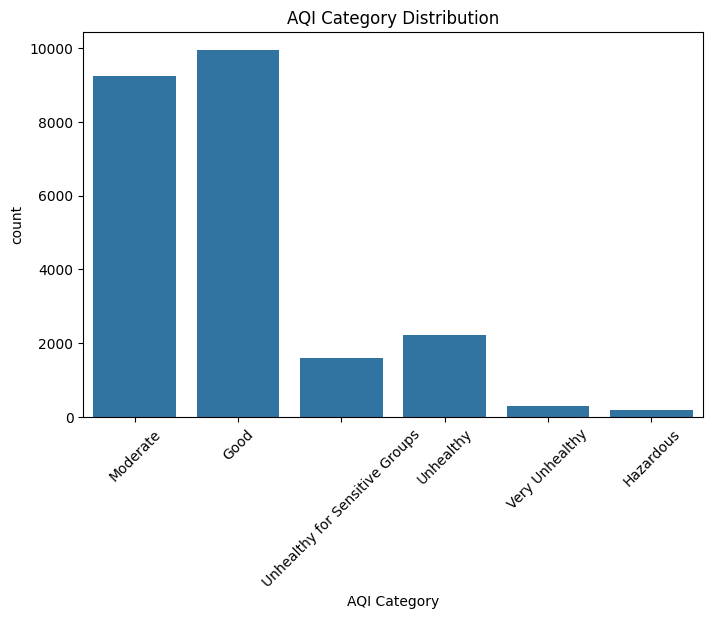

In [50]:
plt.figure(figsize=(8,5))
sns.countplot(x="AQI Category", data=df)
plt.title("AQI Category Distribution")
plt.xticks(rotation=45)
plt.show()

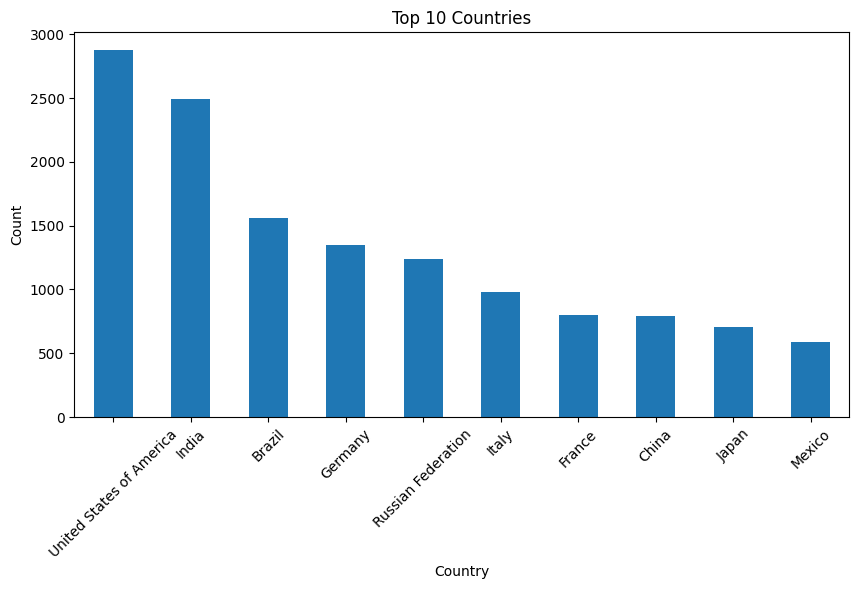

In [43]:
top_countries = df["Country"].value_counts().head(10)

plt.figure(figsize=(10,5))
top_countries.plot(kind="bar")
plt.title("Top 10 Countries")
plt.xlabel("Country")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

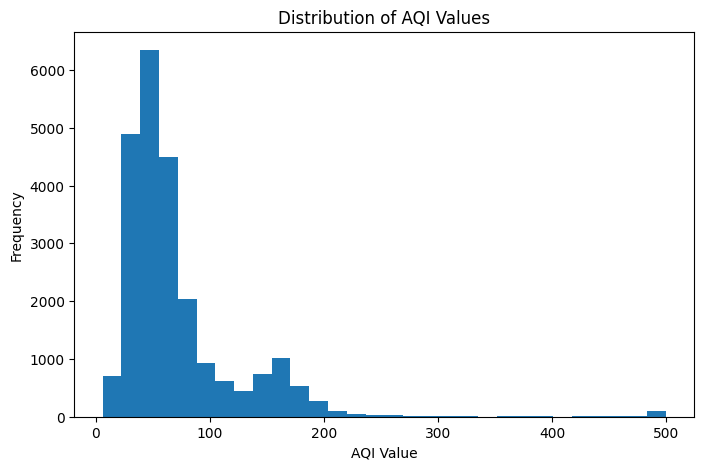

In [44]:
plt.figure(figsize=(8,5))
plt.hist(df["AQI Value"], bins=30)
plt.title("Distribution of AQI Values")
plt.xlabel("AQI Value")
plt.ylabel("Frequency")
plt.show()

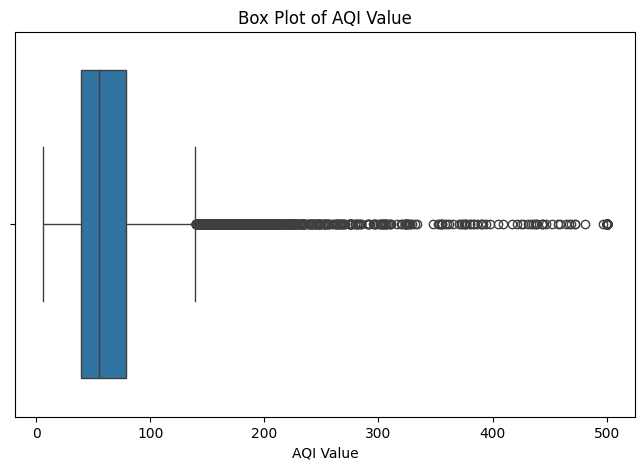

In [45]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["AQI Value"])
plt.title("Box Plot of AQI Value")
plt.show()

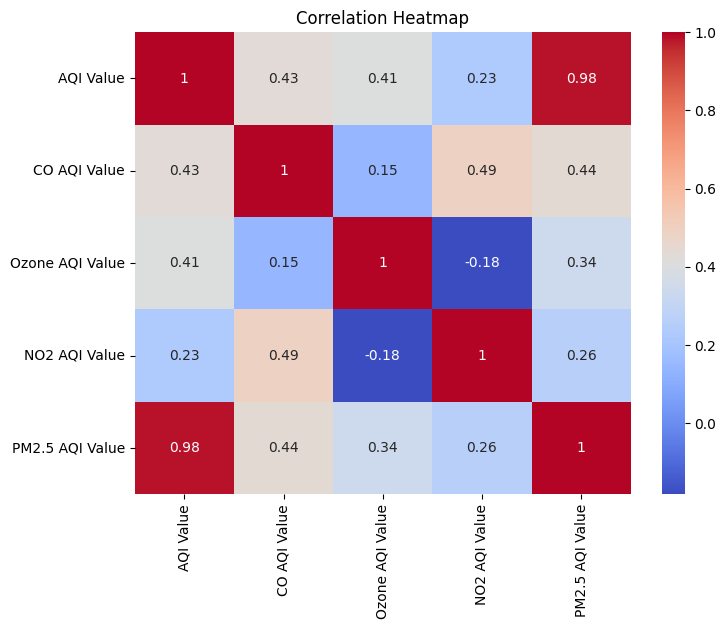

In [46]:
numeric_df = df.select_dtypes(include=["int64","float64"])

plt.figure(figsize=(8,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

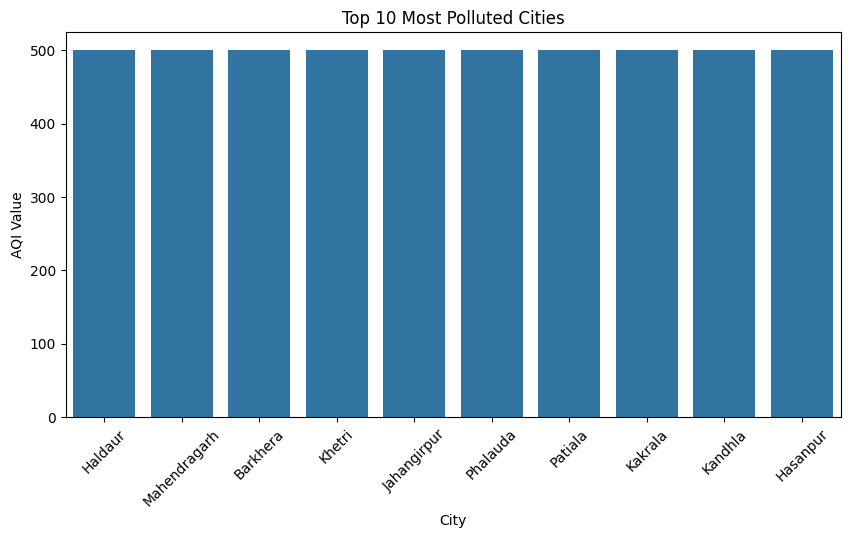

In [47]:
top_cities = df.sort_values("AQI Value", ascending=False).head(10)

plt.figure(figsize=(10,5))
sns.barplot(x="City", y="AQI Value", data=top_cities)

plt.xticks(rotation=45)
plt.title("Top 10 Most Polluted Cities")
plt.show()

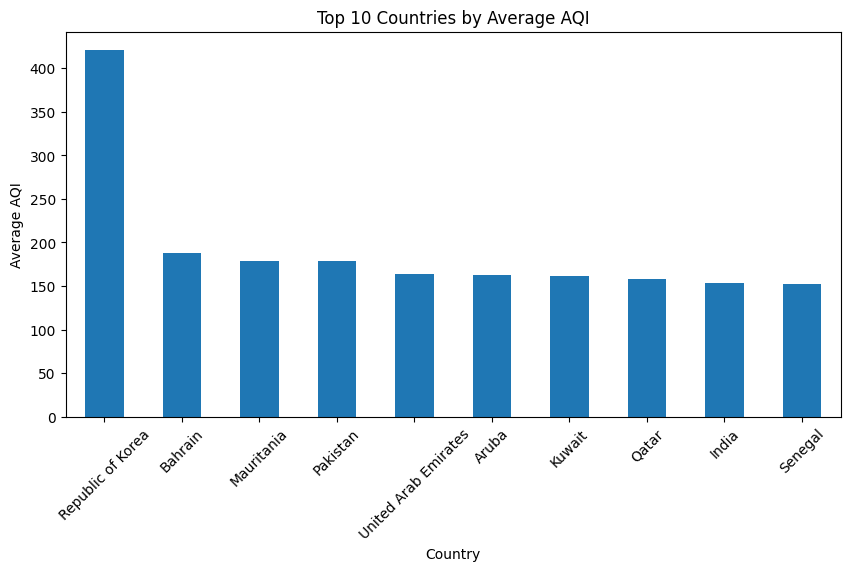

In [48]:
country_aqi = df.groupby("Country")["AQI Value"].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
country_aqi.plot(kind="bar")

plt.title("Top 10 Countries by Average AQI")
plt.ylabel("Average AQI")
plt.xticks(rotation=45)

plt.show()

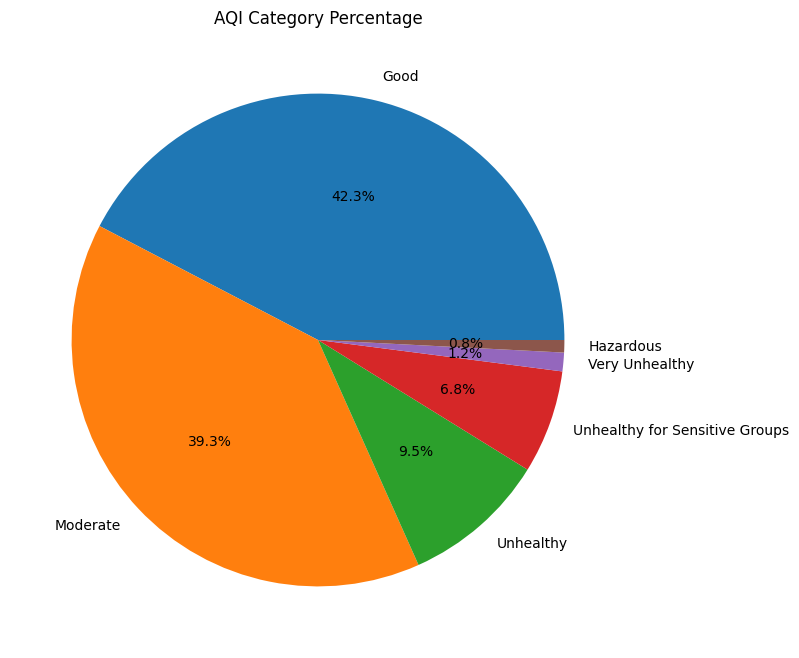

In [49]:
plt.figure(figsize=(8,8))

df["AQI Category"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("AQI Category Percentage")
plt.ylabel("")

plt.show()